<a href="https://colab.research.google.com/github/Nanzz1112/Tugas2_AI/blob/main/prediksi_emas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import files

uploaded = files.upload()

Saving xauusd_gold_dataset.csv.csv to xauusd_gold_dataset.csv (1).csv


In [8]:
import pandas as pd

data = pd.read_csv("xauusd_gold_dataset.csv.csv")

print("Dataset berhasil dibaca!")
print(data.head())
print("\nNama kolom:")
print(data.columns.tolist())

Dataset berhasil dibaca!
     datetime    open    high     low   close   returns  volatility_30  \
0  1979-12-26  499.00  499.00  499.00  499.00       NaN            NaN   
1  1979-12-27  515.50  515.50  515.50  515.50  0.033066            NaN   
2  1979-12-28  512.00  512.00  512.00  512.00 -0.006790            NaN   
3  1980-01-01  512.00  512.00  512.00  512.00  0.000000            NaN   
4  1980-01-02  559.75  559.75  559.75  559.75  0.093262            NaN   

   sma_20  sma_50      ema_20  ...  bb_lower  trend  target_next_close  \
0     NaN     NaN  499.000000  ...       NaN      0             515.50   
1     NaN     NaN  500.571429  ...       NaN      0             512.00   
2     NaN     NaN  501.659864  ...       NaN      0             512.00   
3     NaN     NaN  502.644639  ...       NaN      0             559.75   
4     NaN     NaN  508.083245  ...       NaN      0             634.25   

   target_direction  log_returns  lag_1  lag_2  lag_3  return_7  return_14  
0       

Library berhasil diimpor!

Dataset berhasil dibaca!
Ukuran dataset: (12096, 27)

Lima data pertama:
     datetime    open    high     low   close   returns  volatility_30  \
0  1979-12-26  499.00  499.00  499.00  499.00       NaN            NaN   
1  1979-12-27  515.50  515.50  515.50  515.50  0.033066            NaN   
2  1979-12-28  512.00  512.00  512.00  512.00 -0.006790            NaN   
3  1980-01-01  512.00  512.00  512.00  512.00  0.000000            NaN   
4  1980-01-02  559.75  559.75  559.75  559.75  0.093262            NaN   

   sma_20  sma_50      ema_20  ...  bb_lower  trend  target_next_close  \
0     NaN     NaN  499.000000  ...       NaN      0             515.50   
1     NaN     NaN  500.571429  ...       NaN      0             512.00   
2     NaN     NaN  501.659864  ...       NaN      0             512.00   
3     NaN     NaN  502.644639  ...       NaN      0             559.75   
4     NaN     NaN  508.083245  ...       NaN      0             634.25   

   target_

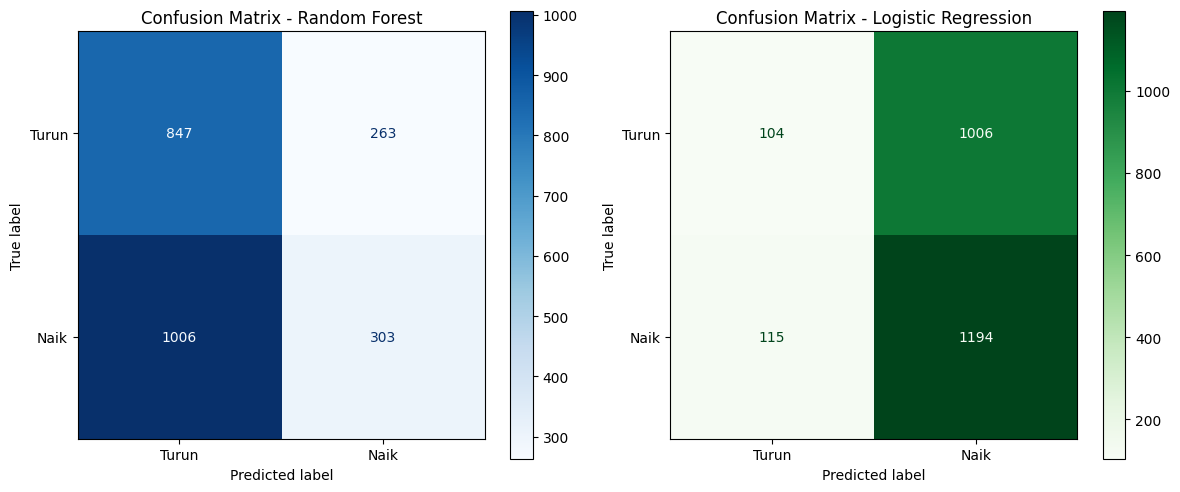

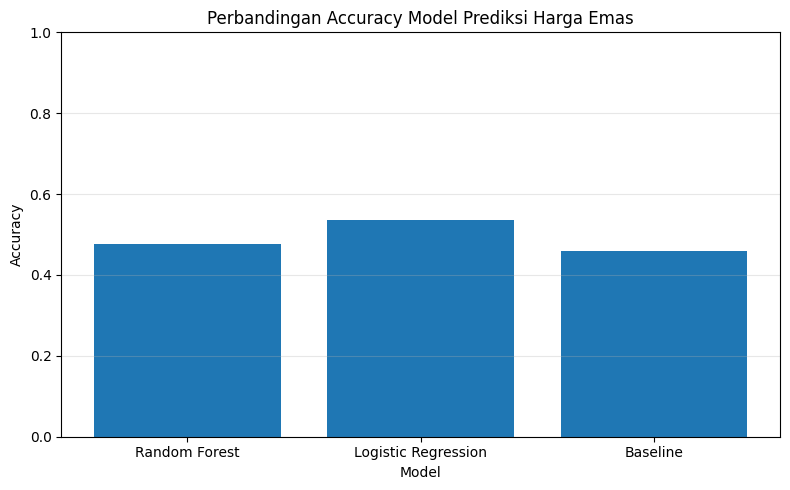


========== FEATURE IMPORTANCE ==========
  Fitur  Importance
returns    0.148552
  lag_3    0.136589
  lag_2    0.134095
  lag_1    0.120340
    low    0.116256
   high    0.116241
  close    0.114832
   open    0.113095


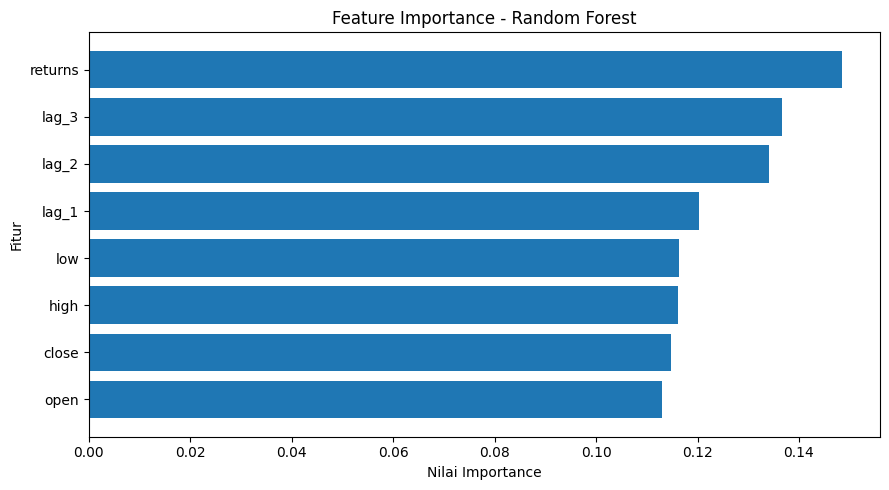


========== 10 CONTOH PREDIKSI TERAKHIR ==========
             open        high         low       close       returns       lag_1       lag_2       lag_3 Harga_Aktual_Arah Prediksi_Random_Forest Prediksi_Logistic_Regression
12085  5019.68973  5032.13817  5018.90060  5019.79532  5.876737e-07  5019.79237  5020.31894  5083.42129             Turun                  Turun                         Naik
12086  5019.68973  5036.81037  4966.61001  5012.64443 -1.424538e-03  5019.79532  5019.79237  5020.31894             Turun                  Turun                         Naik
12087  5012.46151  5042.92294  4978.14194  4998.97830 -2.726331e-03  5012.64443  5019.79532  5019.79237             Turun                  Turun                         Naik
12088  4998.63708  5016.82098  4837.58291  4841.92773 -3.141653e-02  4998.97830  5012.64443  5019.79532             Turun                  Turun                         Naik
12089  4842.10656  4868.11576  4514.89843  4637.62973 -4.219353e-02  4841.92773

In [10]:
# ============================================================
# PREDIKSI ARAH HARGA EMAS MENGGUNAKAN MACHINE LEARNING
# Model: Random Forest dan Logistic Regression
# Dataset: xauusd_gold_dataset.csv.csv
# ============================================================

# 1. IMPORT LIBRARY
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Library berhasil diimpor!")

# ============================================================
# 2. MEMBACA DATASET
# ============================================================

nama_file = "/content/xauusd_gold_dataset.csv.csv"

if not os.path.exists(nama_file):
    raise FileNotFoundError(
        "File tidak ditemukan. Pastikan xauusd_gold_dataset.csv.csv "
        "sudah diunggah ke Google Colab."
    )

data = pd.read_csv(nama_file)

print("\nDataset berhasil dibaca!")
print("Ukuran dataset:", data.shape)
print("\nLima data pertama:")
print(data.head())

# ============================================================
# 3. MEMBERSIHKAN NAMA KOLOM
# ============================================================

data.columns = (
    data.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

print("\nNama kolom dataset:")
print(data.columns.tolist())

# Mengurutkan data berdasarkan tanggal jika kolom tanggal tersedia
kolom_tanggal = None

for kolom in ["date", "datetime", "timestamp", "time"]:
    if kolom in data.columns:
        kolom_tanggal = kolom
        break

if kolom_tanggal is not None:
    data[kolom_tanggal] = pd.to_datetime(
        data[kolom_tanggal], errors="coerce"
    )
    data = data.dropna(subset=[kolom_tanggal])
    data = data.sort_values(kolom_tanggal).reset_index(drop=True)
    print("\nData diurutkan berdasarkan:", kolom_tanggal)

# ============================================================
# 4. MEMERIKSA TARGET
# ============================================================

target = "target_direction"

if target not in data.columns:
    raise ValueError(
        "Kolom 'target_direction' tidak ditemukan.\n"
        "Kolom yang tersedia: " + str(data.columns.tolist()) +
        "\nPeriksa nama kolom dataset."
    )

# ============================================================
# 5. MENENTUKAN FITUR
# ============================================================

fitur_diinginkan = [
    "open",
    "high",
    "low",
    "close",
    "returns",
    "lag_1",
    "lag_2",
    "lag_3"
]

fitur = [kolom for kolom in fitur_diinginkan if kolom in data.columns]

if len(fitur) == 0:
    raise ValueError(
        "Tidak ditemukan fitur yang sesuai.\n"
        "Kolom dataset: " + str(data.columns.tolist())
    )

# Tidak menggunakan target_next_close karena merupakan informasi harga masa depan
print("\nFitur yang digunakan:")
print(fitur)

# Mengubah fitur menjadi angka
for kolom in fitur:
    data[kolom] = pd.to_numeric(data[kolom], errors="coerce")

data[target] = pd.to_numeric(data[target], errors="coerce")

# Menghapus data yang memiliki nilai kosong pada fitur atau target
data = data.dropna(subset=fitur + [target]).copy()

# Menggunakan target biner 0 dan 1 saja
data = data[data[target].isin([0, 1])].copy()
data[target] = data[target].astype(int)

if data[target].nunique() < 2:
    raise ValueError(
        "Target hanya memiliki satu kelas (0 atau 1). "
        "Periksa isi kolom target_direction."
    )

print("\nJumlah data setelah dibersihkan:", len(data))
print("\nDistribusi target:")
print(data[target].value_counts().sort_index())

# ============================================================
# 6. MEMBAGI DATA BERDASARKAN URUTAN WAKTU
# ============================================================

X = data[fitur]
y = data[target]

batas = int(len(data) * 0.8)

if batas <= 0 or batas >= len(data):
    raise ValueError("Jumlah data tidak cukup untuk pembagian 80:20.")

X_train = X.iloc[:batas]
X_test = X.iloc[batas:]

y_train = y.iloc[:batas]
y_test = y.iloc[batas:]

print("\nJumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

# ============================================================
# 7. MELATIH MODEL RANDOM FOREST
# ============================================================

model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model_rf.fit(X_train, y_train)

prediksi_rf = model_rf.predict(X_test)

print("\nModel Random Forest berhasil dilatih!")

# ============================================================
# 8. MELATIH MODEL LOGISTIC REGRESSION
# ============================================================

model_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

model_lr.fit(X_train, y_train)

prediksi_lr = model_lr.predict(X_test)

print("Model Logistic Regression berhasil dilatih!")

# ============================================================
# 9. MEMBUAT MODEL BASELINE PEMBANDING
# ============================================================

model_baseline = DummyClassifier(strategy="most_frequent")
model_baseline.fit(X_train, y_train)

prediksi_baseline = model_baseline.predict(X_test)

# ============================================================
# 10. EVALUASI MODEL
# ============================================================

def evaluasi_model(nama, aktual, prediksi):
    return {
        "Model": nama,
        "Accuracy": accuracy_score(aktual, prediksi),
        "Precision": precision_score(
            aktual, prediksi, zero_division=0
        ),
        "Recall": recall_score(
            aktual, prediksi, zero_division=0
        ),
        "F1-Score": f1_score(
            aktual, prediksi, zero_division=0
        )
    }

hasil = []

hasil.append(evaluasi_model(
    "Random Forest", y_test, prediksi_rf
))

hasil.append(evaluasi_model(
    "Logistic Regression", y_test, prediksi_lr
))

hasil.append(evaluasi_model(
    "Baseline", y_test, prediksi_baseline
))

hasil_df = pd.DataFrame(hasil)

print("\n========== HASIL EVALUASI MODEL ==========")
print(hasil_df.round(4).to_string(index=False))

# ============================================================
# 11. CLASSIFICATION REPORT
# ============================================================

print("\n========== CLASSIFICATION REPORT: RANDOM FOREST ==========")
print(classification_report(
    y_test,
    prediksi_rf,
    labels=[0, 1],
    target_names=["Turun (0)", "Naik (1)"],
    zero_division=0
))

print("\n========== CLASSIFICATION REPORT: LOGISTIC REGRESSION ==========")
print(classification_report(
    y_test,
    prediksi_lr,
    labels=[0, 1],
    target_names=["Turun (0)", "Naik (1)"],
    zero_division=0
))

# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    prediksi_rf,
    labels=[0, 1],
    display_labels=["Turun", "Naik"],
    cmap="Blues",
    ax=ax[0]
)

ax[0].set_title("Confusion Matrix - Random Forest")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    prediksi_lr,
    labels=[0, 1],
    display_labels=["Turun", "Naik"],
    cmap="Greens",
    ax=ax[1]
)

ax[1].set_title("Confusion Matrix - Logistic Regression")

plt.tight_layout()
plt.show()

# ============================================================
# 13. GRAFIK PERBANDINGAN ACCURACY
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    hasil_df["Model"],
    hasil_df["Accuracy"]
)

plt.title("Perbandingan Accuracy Model Prediksi Harga Emas")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 14. FEATURE IMPORTANCE RANDOM FOREST
# ============================================================

kepentingan = pd.DataFrame({
    "Fitur": fitur,
    "Importance": model_rf.feature_importances_
}).sort_values("Importance", ascending=False)

print("\n========== FEATURE IMPORTANCE ==========")
print(kepentingan.to_string(index=False))

plt.figure(figsize=(9, 5))

plt.barh(
    kepentingan["Fitur"][::-1],
    kepentingan["Importance"][::-1]
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Nilai Importance")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

# ============================================================
# 15. MENAMPILKAN CONTOH HASIL PREDIKSI
# ============================================================

contoh = X_test.tail(10).copy()

contoh["Harga_Aktual_Arah"] = y_test.tail(10)
contoh["Prediksi_Random_Forest"] = model_rf.predict(
    X_test.tail(10)
)
contoh["Prediksi_Logistic_Regression"] = model_lr.predict(
    X_test.tail(10)
)

contoh["Harga_Aktual_Arah"] = (
    contoh["Harga_Aktual_Arah"]
    .map({0: "Turun", 1: "Naik"})
)

contoh["Prediksi_Random_Forest"] = (
    contoh["Prediksi_Random_Forest"]
    .map({0: "Turun", 1: "Naik"})
)

contoh["Prediksi_Logistic_Regression"] = (
    contoh["Prediksi_Logistic_Regression"]
    .map({0: "Turun", 1: "Naik"})
)

print("\n========== 10 CONTOH PREDIKSI TERAKHIR ==========")
print(contoh.to_string())

# ============================================================
# 16. MENENTUKAN MODEL DENGAN ACCURACY TERTINGGI
# ============================================================

hasil_urut = hasil_df.sort_values(
    "Accuracy", ascending=False
)

model_terbaik = hasil_urut.iloc[0]

print("\n========== KESIMPULAN ==========")
print("Model dengan accuracy tertinggi:", model_terbaik["Model"])
print("Accuracy:", round(model_terbaik["Accuracy"] * 100, 2), "%")

print("\nPerhatian:")
print(
    "Hasil ini mengukur prediksi arah naik/turun pada data uji, "
    "bukan prediksi nominal harga emas. Accuracy tinggi tidak "
    "menjamin keuntungan investasi."
)